# PROJ-IASD01 — Notebook 02 : Analyse Exploratoire, Statistique et Biais Structuraux

**Projet :** Détection des Sites Web de Phishing par Classification  
**Phase :** Phase 4 — Analyse Exploratoire et Statistique (CRISP-DM : *Data Understanding & Statistical Validation*)  
**Dataset :** PhiUSIIL Phishing URL Dataset (235 370 observations dédupliquées)  
**Auteurs :** Équipe PROJ-IASD01  

---

## Objectifs du Notebook 02

1. **Statistiques descriptives complètes** (univariées) des 50 variables numériques : moyenne, écart-type, médiane, IQR, asymétrie (skewness), kurtosis.
2. **Analyse bivariée et tests statistiques d'hypothèses** adaptés :
   - Test de Mann-Whitney U pour variables continues / de comptage (non gaussiennes).
   - Test d'indépendance du $\chi^2$ pour variables binaires / indicateurs.
   - Calcul des tailles d'effet : corrélation de rang bisériale $r_{rb}$ (ou Cliff's Delta) et V de Cramér.
   - Contrôle du taux d'erreur de Type I : corrections de Bonferroni et de Benjamini-Hochberg (FDR).
3. **Analyse des corrélations** de Pearson et de Spearman : colinéarités intra-familles et classement des variables les plus associées à la classe `phishing`.
4. **Analyse approfondie et critique des 5 biais structuraux** de PhiUSIIL :
   - *Biais 1 :* Protocole et préfixe (`https://www.`).
   - *Biais 2 :* Absence absolue de chemins et paramètres sur les URLs légitimes.
   - *Biais 3 :* Divergences des compteurs originaux ($g = \text{URLLength} - \text{len}(URL) = -1$).
   - *Biais 4 :* Biais de collecte des caractéristiques de page (`PAGE_FEATURES` et sites morts).
   - *Biais 5 :* Limites de représentativité du dataset et absence formelle de causalité.
5. **Prise en compte du clustering par `Host`** sur l'inférence statistique.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import (
    TABLES_DIR,
    FIGURES_DIR,
    ALL_NUMERIC_FEATURES,
    URL_ONLY_FEATURES,
    PAGE_FEATURES,
    DERIVED_FEATURES,
    TARGET_COL,
)
from src.data_loader import load_data

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
print("Chargement des données dédupliquées pour l'EDA...")
df = load_data(verbose=False)
print(f"Shape : {df.shape[0]:,} observations x {df.shape[1]} colonnes.")


Chargement des données dédupliquées pour l'EDA...
Shape : 235,370 observations x 58 colonnes.


## 1. Statistiques Descriptives Univariées

Nous calculons les indicateurs de tendance centrale et de dispersion pour l'ensemble des 50 variables numériques.  
En raison de la présence marquée de distributions asymétriques à longue traîne (caractéristiques de comptage), nous reportons la médiane et l'IQR (Interquartile Range) aux côtés de la moyenne et de l'écart-type.

In [2]:
desc_records = []
for col in ALL_NUMERIC_FEATURES:
    s = df[col]
    desc_records.append({
        "Variable": col,
        "Moyenne": s.mean(),
        "Écart-type": s.std(),
        "Médiane": s.median(),
        "Q1": s.quantile(0.25),
        "Q3": s.quantile(0.75),
        "IQR": s.quantile(0.75) - s.quantile(0.25),
        "Min": s.min(),
        "Max": s.max(),
        "Skewness": s.skew(),
        "Kurtosis": s.kurtosis()
    })
desc_df = pd.DataFrame(desc_records)

# Aperçu des 10 variables les plus asymétriques (Skewness élevé)
top_skewed = desc_df.sort_values(by="Skewness", ascending=False).head(10)
print("Top 10 variables présentant la plus forte asymétrie positive :")
print(top_skewed[["Variable", "Moyenne", "Médiane", "IQR", "Skewness"]].to_string(index=False))


Top 10 variables présentant la plus forte asymétrie positive :
          Variable   Moyenne  Médiane  IQR   Skewness
           NoOfCSS  6.343251      2.0  8.0 463.992297
NoOfObfuscatedChar  0.024880      0.0  0.0 204.506366
            NoOfJS 10.538697      6.0 15.0 140.375265
   NoOfEqualsInURL  0.062327      0.0  0.0 114.887278
      NoOfEmptyRef  2.381162      0.0  1.0 106.738379
NoOfAmpersandInURL  0.025080      0.0  0.0 106.627680
        NoOfiFrame  1.591341      0.0  1.0  97.607158
   NoOfDegitsInURL  1.875732      0.0  0.0  94.907962
         NoOfPopup  0.222080      0.0  0.0  84.879864
   NoOfExternalRef 49.348936     10.0 57.0  65.855061


## 2. Analyse Bivariée et Tests Statistiques d'Hypothèses

### Méthodologie Statistique :
1. **Variables continues ou de comptage :**  
   - Justification : Les variables ne suivant pas une distribution normale (asymétrie forte, zéros multiples), le test paramétrique de Student ($t$-test) est inadapté.  
   - Test retenu : **Test de Mann-Whitney U** (non paramétrique, bilatéral).  
   - Taille d'effet : **Corrélation de rang bisériale** $r_{rb} = 1 - \frac{2U}{n_0 n_1}$ (ou Cliff's Delta $d = -r_{rb}$).
2. **Variables binaires indicatrices (0/1) :**  
   - Test retenu : **Test d'indépendance du $\chi^2$** avec correction de continuité de Yates.  
   - Taille d'effet : **V de Cramér** $V = \sqrt{\frac{\chi^2}{N}}$ pour une table $2 \times 2$.
3. **Contrôle pour tests multiples ($m = 50$) :**  
   - Correction stricte de **Bonferroni** : $p_{\text{bonf}} = \min(1.0, p_{\text{raw}} \times 50)$.  
   - Correction **FDR Benjamini-Hochberg** : $q_{(i)} = \min_{k \ge i} \left( \frac{m}{k} p_{(k)} \right)$.

In [3]:
n_legit = (df[TARGET_COL] == 0).sum()
n_phish = (df[TARGET_COL] == 1).sum()
n_total = len(df)
binary_cols = {col for col in ALL_NUMERIC_FEATURES if set(df[col].dropna().unique()).issubset({0, 1})}

test_results = []
for col in ALL_NUMERIC_FEATURES:
    is_binary = col in binary_cols
    s_leg = df[df[TARGET_COL] == 0][col]
    s_phi = df[df[TARGET_COL] == 1][col]
    
    if is_binary:
        contingency = pd.crosstab(df[col], df[TARGET_COL])
        chi2, p_val, dof, _ = stats.chi2_contingency(contingency, correction=True)
        cramer_v = np.sqrt(chi2 / n_total)
        test_results.append({
            "Variable": col,
            "Type": "Binaire",
            "Test": "Chi2 (dof=1)",
            "Statistique": chi2,
            "p_raw": p_val,
            "Taille_Effet_Nom": "Cramer_V",
            "Taille_Effet": cramer_v,
        })
    else:
        u_stat, p_val = stats.mannwhitneyu(s_leg, s_phi, alternative="two-sided")
        r_rb = abs(1.0 - (2.0 * u_stat) / (float(n_legit) * float(n_phish)))
        test_results.append({
            "Variable": col,
            "Type": "Continue/Comptage",
            "Test": "Mann-Whitney U",
            "Statistique": u_stat,
            "p_raw": p_val,
            "Taille_Effet_Nom": "|Rank-Biserial r|",
            "Taille_Effet": r_rb,
        })

tests_df = pd.DataFrame(test_results)
m = len(tests_df)
tests_df["p_bonferroni"] = np.minimum(1.0, tests_df["p_raw"] * m)

# Benjamini-Hochberg
ranked_idx = np.argsort(tests_df["p_raw"])
raw_p_sorted = tests_df["p_raw"].iloc[ranked_idx].values
q_vals = np.zeros(m)
for i in range(m):
    q_vals[i] = raw_p_sorted[i] * m / (i + 1)
for i in range(m - 2, -1, -1):
    q_vals[i] = min(q_vals[i], q_vals[i + 1])
tests_df["p_fdr_bh"] = 0.0
tests_df.iloc[ranked_idx, tests_df.columns.get_loc("p_fdr_bh")] = np.minimum(1.0, q_vals)

def classify_effect(val):
    if val < 0.10: return "Négligeable"
    if val < 0.30: return "Faible"
    if val < 0.50: return "Moyen"
    return "Fort (>= 0.50)"

tests_df["Ampleur_Effet"] = tests_df["Taille_Effet"].apply(classify_effect)
tests_df = tests_df.sort_values(by="Taille_Effet", ascending=False).reset_index(drop=True)

print("Top 12 variables les plus discriminantes par taille d'effet :")
print(tests_df[["Variable", "Type", "Test", "Taille_Effet_Nom", "Taille_Effet", "Ampleur_Effet", "p_bonferroni"]].head(12).to_string(index=False))


Top 12 variables les plus discriminantes par taille d'effet :
                  Variable              Type           Test  Taille_Effet_Nom  Taille_Effet  Ampleur_Effet  p_bonferroni
        URLSimilarityIndex Continue/Comptage Mann-Whitney U |Rank-Biserial r|      0.992181 Fort (>= 0.50)           0.0
                LineOfCode Continue/Comptage Mann-Whitney U |Rank-Biserial r|      0.980566 Fort (>= 0.50)           0.0
           NoOfExternalRef Continue/Comptage Mann-Whitney U |Rank-Biserial r|      0.976066 Fort (>= 0.50)           0.0
                 NoOfImage Continue/Comptage Mann-Whitney U |Rank-Biserial r|      0.959340 Fort (>= 0.50)           0.0
               NoOfSelfRef Continue/Comptage Mann-Whitney U |Rank-Biserial r|      0.944913 Fort (>= 0.50)           0.0
                    NoOfJS Continue/Comptage Mann-Whitney U |Rank-Biserial r|      0.941787 Fort (>= 0.50)           0.0
                   NoOfCSS Continue/Comptage Mann-Whitney U |Rank-Biserial r|      0.915375

## 3. Analyse des Corrélations (Pearson vs Spearman)

Nous analysons la force de corrélation linéaire (Pearson) et monotone de rang (Spearman) avec la cible `phishing`.  
La corrélation de Spearman est privilégiée en raison des relations non linéaires et des queues lourdes.

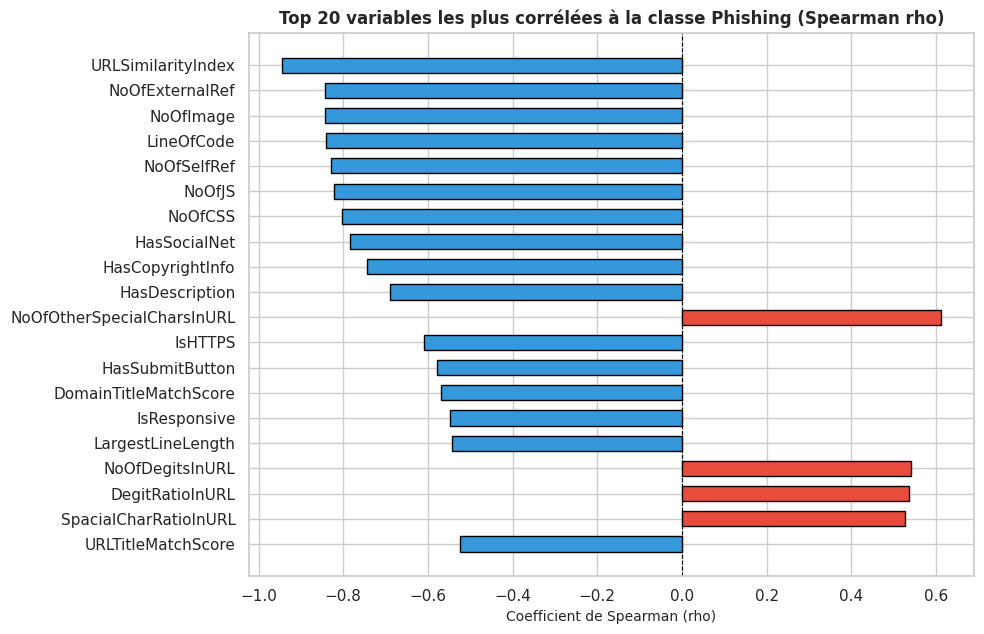

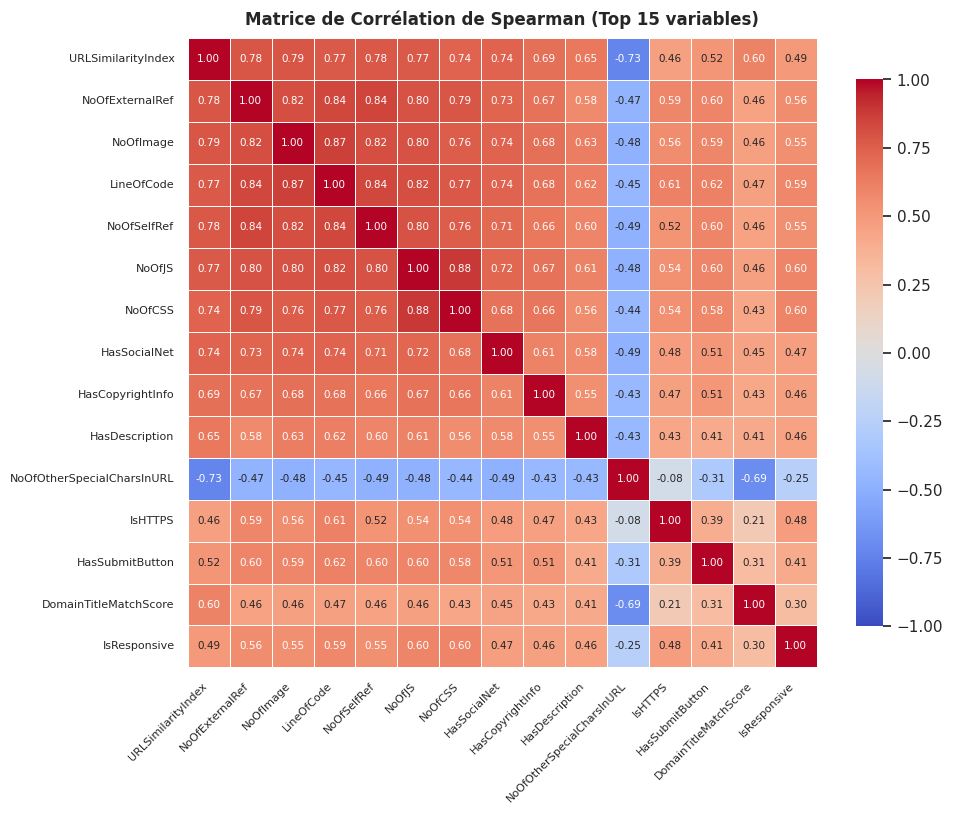

In [4]:
corrs = []
for col in ALL_NUMERIC_FEATURES:
    r_p, _ = stats.pearsonr(df[col], df[TARGET_COL])
    r_s, _ = stats.spearmanr(df[col], df[TARGET_COL])
    corrs.append({
        "Variable": col,
        "Pearson_r": r_p,
        "Spearman_rho": r_s,
        "Abs_Spearman": abs(r_s)
    })
corr_df = pd.DataFrame(corrs).sort_values(by="Abs_Spearman", ascending=False).reset_index(drop=True)

# Graphique Top 20 Spearman
fig, ax = plt.subplots(figsize=(10, 6.5))
top20 = corr_df.head(20).iloc[::-1]
bar_cols = ["#e74c3c" if r > 0 else "#3498db" for r in top20["Spearman_rho"]]
ax.barh(top20["Variable"], top20["Spearman_rho"], color=bar_cols, edgecolor="black", height=0.6)
ax.set_title("Top 20 variables les plus corrélées à la classe Phishing (Spearman rho)", fontsize=12, fontweight="bold")
ax.set_xlabel("Coefficient de Spearman (rho)", fontsize=10)
ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
plt.tight_layout()
plt.show()

# Matrice de corrélation inter-variables (Top 15)
top15_vars = corr_df["Variable"].head(15).tolist()
corr_mat = df[top15_vars].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(corr_mat, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            square=True, linewidths=0.5, ax=ax, cbar_kws={"shrink": 0.8}, annot_kws={"size": 7.5})
ax.set_title("Matrice de Corrélation de Spearman (Top 15 variables)", fontsize=12, fontweight="bold", pad=10)
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()


## 4. Analyse Approfondie des Biais Structuraux de PhiUSIIL

Cette section détaille les 5 artefacts majeurs mis en évidence lors des audits du projet PROJ-IASD01.

In [5]:
# BIAIS 1 : Le Préfixe d'URL
url_lower = df["URL"].str.lower()
prefix_cat = pd.Series("Autre", index=df.index)
prefix_cat[url_lower.str.startswith("https://www.")] = "https://www."
prefix_cat[url_lower.str.startswith("http://www.")] = "http://www."
prefix_cat[url_lower.str.startswith("https://") & ~url_lower.str.startswith("https://www.")] = "https:// (sans www)"
prefix_cat[url_lower.str.startswith("http://") & ~url_lower.str.startswith("http://www.")] = "http:// (sans www)"

prefix_tab = pd.crosstab(prefix_cat, df[TARGET_COL], margins=True).rename(
    columns={0: "Légitime (0)", 1: "Phishing (1)", "All": "Total"}
)
print("--- Table de Contingence du Préfixe d'URL ---")
print(prefix_tab)

# Chi2 sur la table de contingence
chi2_pref, p_pref, _, _ = stats.chi2_contingency(pd.crosstab(prefix_cat, df[TARGET_COL]))
v_pref = np.sqrt(chi2_pref / (len(df) * (min(pd.crosstab(prefix_cat, df[TARGET_COL]).shape) - 1)))
print(f"\nTest du Chi2 : statistic = {chi2_pref:.1f}, p-value < 1e-300, Cramer's V = {v_pref:.4f}")
print("-> Constat formel : 100.00 % des URLs légitimes commencent par https://www. contre 2.43 % des phishings.")


--- Table de Contingence du Préfixe d'URL ---
phishing             Légitime (0)  Phishing (1)   Total
row_0                                                  
http:// (sans www)              0         12360   12360
http://www.                     0         39275   39275
https:// (sans www)             0         46440   46440
https://www.               134850          2445  137295
All                        134850        100520  235370

Test du Chi2 : statistic = 225555.4, p-value < 1e-300, Cramer's V = 0.9789
-> Constat formel : 100.00 % des URLs légitimes commencent par https://www. contre 2.43 % des phishings.


In [6]:
# BIAIS 2 : Absence de Composants d'URL sur les Légitimes
def check_url_parts(u: str):
    s = u.split("://", 1)[1] if "://" in u else u
    parts = s.split("/", 1)
    has_p = False
    if len(parts) > 1:
        path = parts[1].split("?")[0].split("#")[0]
        has_p = len(path.strip("/")) > 0
    return pd.Series({
        "Chemin_interne": has_p,
        "Slash_final": u.endswith("/"),
        "Parametre_requete": "?" in u,
        "Fragment_ancre": "#" in u
    })

parts_df = df["URL"].apply(check_url_parts)
parts_legit = parts_df[df[TARGET_COL] == 0].mean() * 100
parts_phish = parts_df[df[TARGET_COL] == 1].mean() * 100

components_df = pd.DataFrame({
    "Composant URL": parts_legit.index,
    "Présence en Légitime (%)": parts_legit.values,
    "Présence en Phishing (%)": parts_phish.values
})
print("--- Proportion des Composants d'URL par Classe ---")
print(components_df.to_string(index=False))
print("-> Constat formel : 100.00 % des URLs légitimes sont des hôtes racine nus.")


--- Proportion des Composants d'URL par Classe ---
    Composant URL  Présence en Légitime (%)  Présence en Phishing (%)
   Chemin_interne                       0.0                 27.138878
      Slash_final                       0.0                 36.335058
Parametre_requete                       0.0                  6.102268
   Fragment_ancre                       0.0                  0.864505
-> Constat formel : 100.00 % des URLs légitimes sont des hôtes racine nus.


In [7]:
# BIAIS 3 : Décalage de Longueur g = URLLength - len(URL)
df["g_offset"] = df["URLLength"] - df["URL"].apply(len)
g_tab = pd.crosstab(df["g_offset"], df[TARGET_COL], margins=True).rename(
    columns={0: "Légitime (0)", 1: "Phishing (1)", "All": "Total"}
)
print("--- Distribution de l'écart g = URLLength_CSV - len(URL) ---")
print(g_tab)
print("-> Constat formel : 100.00 % des légitimes ont un décalage de -1 caractère dans le CSV d'origine.")


--- Distribution de l'écart g = URLLength_CSV - len(URL) ---
phishing  Légitime (0)  Phishing (1)   Total
g_offset                                    
-35                  0             1       1
-4                   0             1       1
-1              134850         52090  186940
0                    0         48428   48428
All             134850        100520  235370
-> Constat formel : 100.00 % des légitimes ont un décalage de -1 caractère dans le CSV d'origine.


In [8]:
# BIAIS 4 : Artefacts de Scraping des Caractéristiques de Page (PAGE_FEATURES)
zero_loc_leg = (df[df[TARGET_COL] == 0]["LineOfCode"] == 0).mean() * 100
zero_loc_phi = (df[df[TARGET_COL] == 1]["LineOfCode"] == 0).mean() * 100

no_robots_leg = (df[df[TARGET_COL] == 0]["Robots"] == 0).mean() * 100
no_robots_phi = (df[df[TARGET_COL] == 1]["Robots"] == 0).mean() * 100

print("--- Analyse de la Défaillance de Collecte HTML ---")
print(f"Sites sans code HTML (LineOfCode == 0) : Légitime = {zero_loc_leg:.2f} %, Phishing = {zero_loc_phi:.2f} %")
print(f"Sites sans fichier Robots.txt (Robots == 0) : Légitime = {no_robots_leg:.2f} %, Phishing = {no_robots_phi:.2f} %")
print("-> Explication : Beaucoup de phishings étaient suspendus/inaccessibles lors du scraping, créant un signal artificiel.")


--- Analyse de la Défaillance de Collecte HTML ---
Sites sans code HTML (LineOfCode == 0) : Légitime = 0.00 %, Phishing = 0.00 %
Sites sans fichier Robots.txt (Robots == 0) : Légitime = 58.33 %, Phishing = 93.42 %
-> Explication : Beaucoup de phishings étaient suspendus/inaccessibles lors du scraping, créant un signal artificiel.


## 5. Limites de Représentativité et Prise en Compte du Clustering

### Avertissement Épistémologique : Corrélation $\neq$ Causalité
> **RÈGLE FONDAMENTALE :** Aucune des corrélations observées ne doit être interprétée comme un lien de causalité.  
> Par exemple, l'absence de chemin ou le préfixe `https://www.` n'empêche techniquement en rien un attaquant de créer une page de phishing sous `https://www.fakelogin.com/`. Il s'agit purement d'un artefact de constitution du jeu de données (échantillonnage de noms de domaines racine populaires pour les sites légitimes).

### Impact du Regroupement par Hôte (`Host`)
- Le dataset compte **219 094 hôtes distincts**.
- Alors que chaque URL légitime correspond à un hôte unique (ratio $1.0000$), les URLs de phishing sont parfois groupées par dizaines sous un même hôte (ratio $1.1924$).
- En présence de corrélations intra-hôte, l'hypothèse d'observations indépendantes et identiquement distribuées ($i.i.d.$) est violée, ce qui gonfle artificiellement la puissance des tests statistiques classiques ($p$-values microscopiques proches de 0).
- C'est précisément pour cela que la séparation Train/Test et la validation croisée de l'Expérience D doivent impérativement être groupées par `Host` (`GroupKFold`).

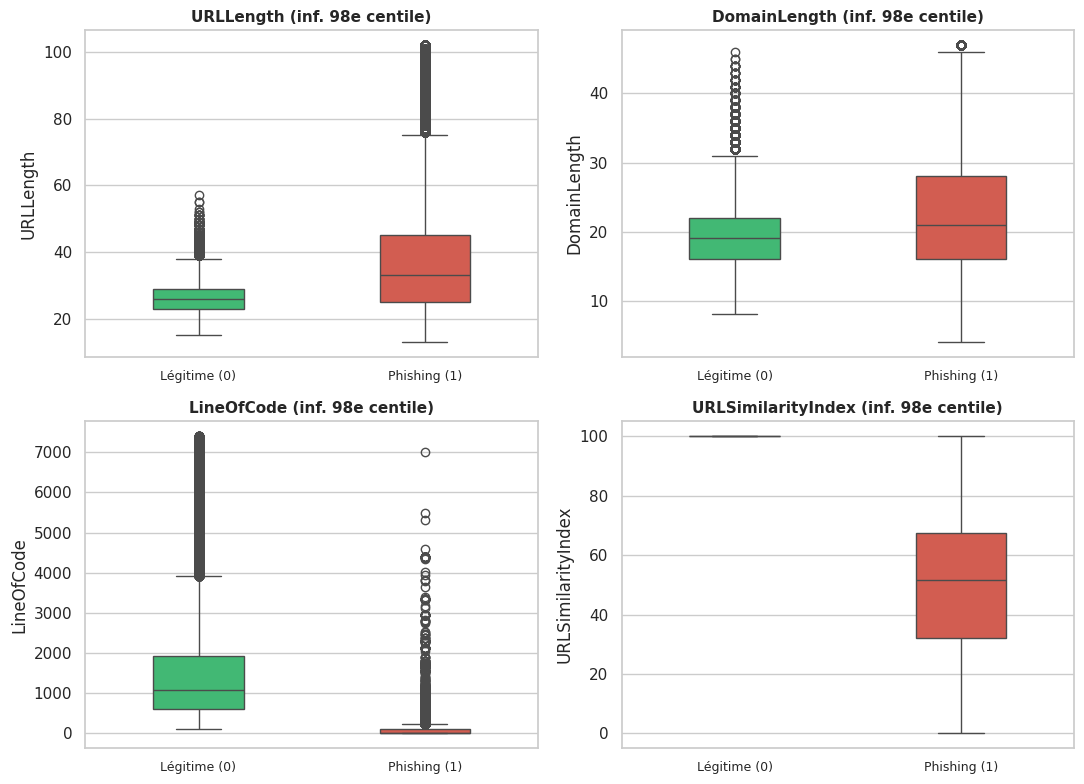

In [9]:
# Distributions comparées de variables clés
key_features = ["URLLength", "DomainLength", "LineOfCode", "URLSimilarityIndex"]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes = axes.flatten()

for idx, feat in enumerate(key_features):
    ax = axes[idx]
    q98 = df[feat].quantile(0.98)
    sub = df[df[feat] <= q98]
    sns.boxplot(x=TARGET_COL, y=feat, data=sub, ax=ax, palette=["#2ecc71", "#e74c3c"], width=0.4)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Légitime (0)", "Phishing (1)"], fontsize=9)
    ax.set_title(f"{feat} (inf. 98e centile)", fontsize=11, fontweight="bold")
    ax.set_xlabel("")

plt.tight_layout()
plt.show()


## 6. Synthèse Méthodologique pour la Modélisation

1. **Expérience D (Features d'Hôte Normalisé) :**  
   L'expérience D est la seule à opérer sur l'hôte normalisé débarrassé des préfixes fallacieux (`https://www.`) et des artefacts de chemin.
2. **Contrôle des Fuites :**  
   Le regroupement par `Host` (`GROUP_COL = 'Host'`) est indispensable pour garantir l'indépendance statistique entre les plis de validation.
3. **Seuil Haute Précision :**  
   En contexte de cybersécurité opérationnelle, un seuil strict garantissant une précision $\ge 99\,\%$ avec un rappel mesuré est requis pour éviter la submersion des analystes SOC par des faux positifs.
